# Лабораторна робота №1
## Базові алгоритми класифікації у Scikit-learn

Виконав: Мартинюк Іван, ФБ-62мп

### Мета роботи

Ознайомитися з базовим workflow задачі класифікації: від вибору та аналізу даних до навчання, налаштування, порівняння та оцінювання моделей машинного навчання з використанням бібліотеки Scikit-learn.

## Датасет RT-IoT2022

Джерело: [UCI Machine Learning Repository: RT-IoT2022](https://archive.ics.uci.edu/dataset/942/rt-iot2022)

Датасет зібраний на IoT-інфраструктурі реального часу. Кожен рядок описує один мережевий потік (flow), а ознаки отримані з трафіку за допомогою Zeek та плагіна Flowmeter: тривалість потоку, кількість пакетів у кожному напрямку, розміри payload, TCP-прапорці, інтервали між пакетами тощо.

Цільова змінна `Attack_type` містить 12 класів:
* звичайний трафік IoT-пристроїв: `Thing_Speak`, `MQTT_Publish`, `Wipro_bulb`;
* атаки: `DOS_SYN_Hping`, `ARP_poisioning`, `DDOS_Slowloris`, `Metasploit_Brute_Force_SSH`, сканування NMAP (`NMAP_UDP_SCAN`, `NMAP_XMAS_TREE_SCAN`, `NMAP_OS_DETECTION`, `NMAP_TCP_scan`, `NMAP_FIN_SCAN`).

Задача: за характеристиками потоку визначити, до якого типу трафіку чи атаки він належить (багатокласова класифікація).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

from sklearn import set_config
set_config(display="text")

## 1. Завантаження та первинний аналіз даних

In [2]:
df = pd.read_csv('rt-iot2022/RT_IOT2022')
df.head()

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


In [3]:
print(df.shape)

(123117, 85)


In [4]:
print(df.columns.tolist())

['Unnamed: 0', 'id.orig_p', 'id.resp_p', 'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flow_pkts_payload.std', 'fwd_iat.min', 'fwd_iat.max', 'fwd_iat.to

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123117 entries, 0 to 123116
Data columns (total 85 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Unnamed: 0                123117 non-null  int64  
 1   id.orig_p                 123117 non-null  int64  
 2   id.resp_p                 123117 non-null  int64  
 3   proto                     123117 non-null  str    
 4   service                   123117 non-null  str    
 5   flow_duration             123117 non-null  float64
 6   fwd_pkts_tot              123117 non-null  int64  
 7   bwd_pkts_tot              123117 non-null  int64  
 8   fwd_data_pkts_tot         123117 non-null  int64  
 9   bwd_data_pkts_tot         123117 non-null  int64  
 10  fwd_pkts_per_sec          123117 non-null  float64
 11  bwd_pkts_per_sec          123117 non-null  float64
 12  flow_pkts_per_sec         123117 non-null  float64
 13  down_up_ratio             123117 non-null  float64
 14 

In [6]:
df.dtypes.value_counts()

float64    56
int64      26
str         3
Name: count, dtype: int64

In [7]:
df.select_dtypes(exclude='number').columns.tolist()

['proto', 'service', 'Attack_type']

Ознаки (features): усі колонки, крім `Attack_type`. Більшість ознак числові (`int64`, `float64`), категоріальні лише `proto` (протокол транспортного рівня) та `service` (сервіс прикладного рівня, визначений Zeek).

Цільова змінна (target): `Attack_type`.

In [8]:
df['Attack_type'].value_counts()

Attack_type
DOS_SYN_Hping                 94659
Thing_Speak                    8108
ARP_poisioning                 7750
MQTT_Publish                   4146
NMAP_UDP_SCAN                  2590
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  534
Wipro_bulb                      253
Metasploit_Brute_Force_SSH       37
NMAP_FIN_SCAN                    28
Name: count, dtype: int64

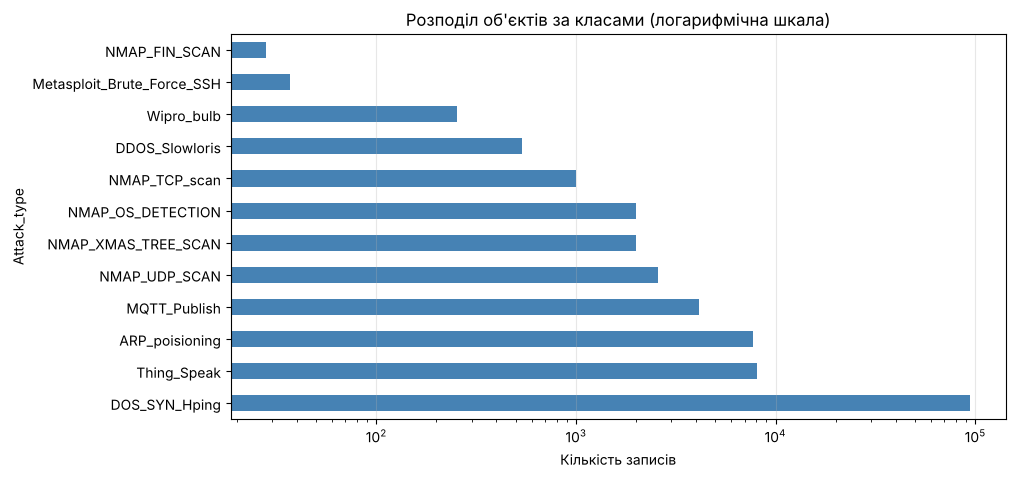

In [9]:
plt.figure(figsize=(10,5))
df['Attack_type'].value_counts().plot(kind='barh', color='steelblue')
plt.xscale('log')
plt.title('Розподіл об\'єктів за класами (логарифмічна шкала)')
plt.xlabel('Кількість записів')
plt.grid(axis='x', alpha=0.3)
plt.show()

Класи сильно незбалансовані: на `DOS_SYN_Hping` припадає 77% усіх записів, а `Metasploit_Brute_Force_SSH` і `NMAP_FIN_SCAN` мають лише 37 і 28 записів. Через це accuracy погано відображає якість моделі, тому далі для порівняння використовується ще й macro F1.

## 2. Попередня обробка даних

In [10]:
df.isnull().sum().sum()

np.int64(0)

Пропущених значень немає, тому заповнення чи видалення пропусків не потрібне.

In [11]:
df[['Unnamed: 0', 'id.orig_p', 'id.resp_p']].head()

,Unnamed: 0,id.orig_p,id.resp_p
0,0,38667,1883
1,1,51143,1883
2,2,44761,1883
3,3,60893,1883
4,4,51087,1883


* `Unnamed: 0` є просто індексом рядка, збережений у CSV, він не несе інформації про трафік.
* `id.orig_p` означає порт джерела. Клієнт обирає його випадково (ephemeral port), тому для типу трафіку ця ознака не має сенсу, а модель могла б «запам'ятати» конкретні порти саме цього запису трафіку.
* `id.resp_p` (порт призначення) залишається, бо він пов'язаний із сервісом, до якого звертаються.

In [12]:
df = df.drop(columns=['Unnamed: 0', 'id.orig_p'])

In [13]:
const_cols = [c for c in df.columns if df[c].nunique() == 1]
const_cols

['bwd_URG_flag_count']

In [14]:
df = df.drop(columns=const_cols)

Ознака з однаковим значенням в усіх рядках нічого не дає моделі, тому її видалено.

In [15]:
df.duplicated().sum()

np.int64(99278)

In [16]:
df[df.duplicated()]['Attack_type'].value_counts()

Attack_type
DOS_SYN_Hping                 94602
ARP_poisioning                 2450
NMAP_UDP_SCAN                  1439
Thing_Speak                     506
NMAP_XMAS_TREE_SCAN             116
NMAP_OS_DETECTION               101
Wipro_bulb                       34
NMAP_FIN_SCAN                    23
MQTT_Publish                      5
DDOS_Slowloris                    1
Metasploit_Brute_Force_SSH        1
Name: count, dtype: int64

Майже 99 тис. рядків повністю повторюють інші рядки, і майже всі вони належать до `DOS_SYN_Hping`. hping3 надсилає однакові SYN-пакети, тому потоки цієї атаки відрізнялися лише портом джерела, який уже видалено. Дублікати не дають моделі нової інформації. Крім того, якщо копії одного рядка потраплять і в train, і в test, модель оцінюватиметься на даних, які вже бачила. Тому дублікати видаляються.

In [17]:
df = df.drop_duplicates()
print(df.shape)
df['Attack_type'].value_counts()

(23839, 82)


Attack_type
Thing_Speak                   7602
ARP_poisioning                5300
MQTT_Publish                  4141
NMAP_OS_DETECTION             1899
NMAP_XMAS_TREE_SCAN           1894
NMAP_UDP_SCAN                 1151
NMAP_TCP_scan                 1002
DDOS_Slowloris                 533
Wipro_bulb                     219
DOS_SYN_Hping                   57
Metasploit_Brute_Force_SSH      36
NMAP_FIN_SCAN                    5
Name: count, dtype: int64

Після видалення дублікатів від `NMAP_FIN_SCAN` залишилось 5 записів. На такій кількості модель не навчиться, а в test потрапив би один запис, тому цей клас видаляється. Решта класів залишаються, хоча `DOS_SYN_Hping` (57) і `Metasploit_Brute_Force_SSH` (36) теж малі.

In [18]:
df = df[df['Attack_type'] != 'NMAP_FIN_SCAN']
print(df.shape)

(23834, 82)


Категоріальні ознаки `proto` та `service` кодуються через `OneHotEncoder`. `LabelEncoder` тут не підходить, бо він задав би штучний порядок між протоколами (наприклад, `icmp` < `tcp` < `udp`), якого насправді немає.

In [19]:
df['proto'].value_counts()

proto
tcp     15293
udp      8507
icmp       34
Name: count, dtype: int64

In [20]:
df['service'].value_counts()

service
dns       7134
-         6427
mqtt      4132
http      3288
ssl       2656
ntp        111
dhcp        29
irc         28
ssh         28
radius       1
Name: count, dtype: int64

In [21]:
ohe = OneHotEncoder(sparse_output=False)
cat_encoded = ohe.fit_transform(df[['proto', 'service']])

cat_df = pd.DataFrame(
    cat_encoded,
    columns=ohe.get_feature_names_out(['proto', 'service']),
    index=df.index
)
cat_df.head()

,proto_icmp,proto_tcp,proto_udp,service_-,service_dhcp,service_dns,service_http,service_irc,service_mqtt,service_ntp,service_radius,service_ssh,service_ssl
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [22]:
df = pd.concat([df.drop(columns=['proto', 'service']), cat_df], axis=1)
print(df.shape)

(23834, 93)


## 3. Візуалізація та дослідження даних (EDA)

Після обробки залишилось понад 90 ознак, тому для візуалізації обрано 14 основних характеристик потоку: тривалість, кількість пакетів, швидкість, розмір payload, інтервали між пакетами, TCP-прапорці, початкові розміри TCP-вікна та порт призначення.

In [23]:
eda_cols = ['id.resp_p', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot',
            'flow_pkts_per_sec', 'payload_bytes_per_second', 'fwd_pkts_payload.avg',
            'bwd_pkts_payload.avg', 'flow_iat.avg', 'down_up_ratio',
            'flow_SYN_flag_count', 'flow_ACK_flag_count',
            'fwd_init_window_size', 'bwd_init_window_size']
df[eda_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
id.resp_p,23834.0,3185.457540,8.886336e+03,0.0,53.000000,443.000000,1883.000000,6.538900e+04
flow_duration,23834.0,18.842910,2.821357e+02,0.0,0.000127,0.060239,4.003963,2.172834e+04
fwd_pkts_tot,23834.0,7.382689,4.885239e+01,0.0,1.000000,2.000000,10.000000,4.345000e+03
bwd_pkts_tot,23834.0,6.208735,7.486736e+01,0.0,1.000000,2.000000,6.000000,1.011200e+04
flow_pkts_per_sec,23834.0,98981.923668,2.858472e+05,0.0,1.209805,39.400894,14269.390988,2.097152e+06
payload_bytes_per_second,23834.0,117270.085822,1.378846e+06,0.0,0.000000,774.647725,4955.975483,1.258291e+08
fwd_pkts_payload.avg,23834.0,36.414032,6.569777e+01,0.0,7.600000,30.571429,43.890152,1.319365e+03
bwd_pkts_payload.avg,23834.0,95.337326,1.685751e+02,0.0,0.000000,48.000000,107.600000,1.457053e+03
flow_iat.avg,23834.0,718982.768761,1.878056e+06,0.0,44.425329,19397.601936,246444.316014,7.283576e+07
down_up_ratio,23834.0,0.828224,3.012395e-01,0.0,0.700000,1.000000,1.000000,6.087899e+00


### Heatmap кореляцій

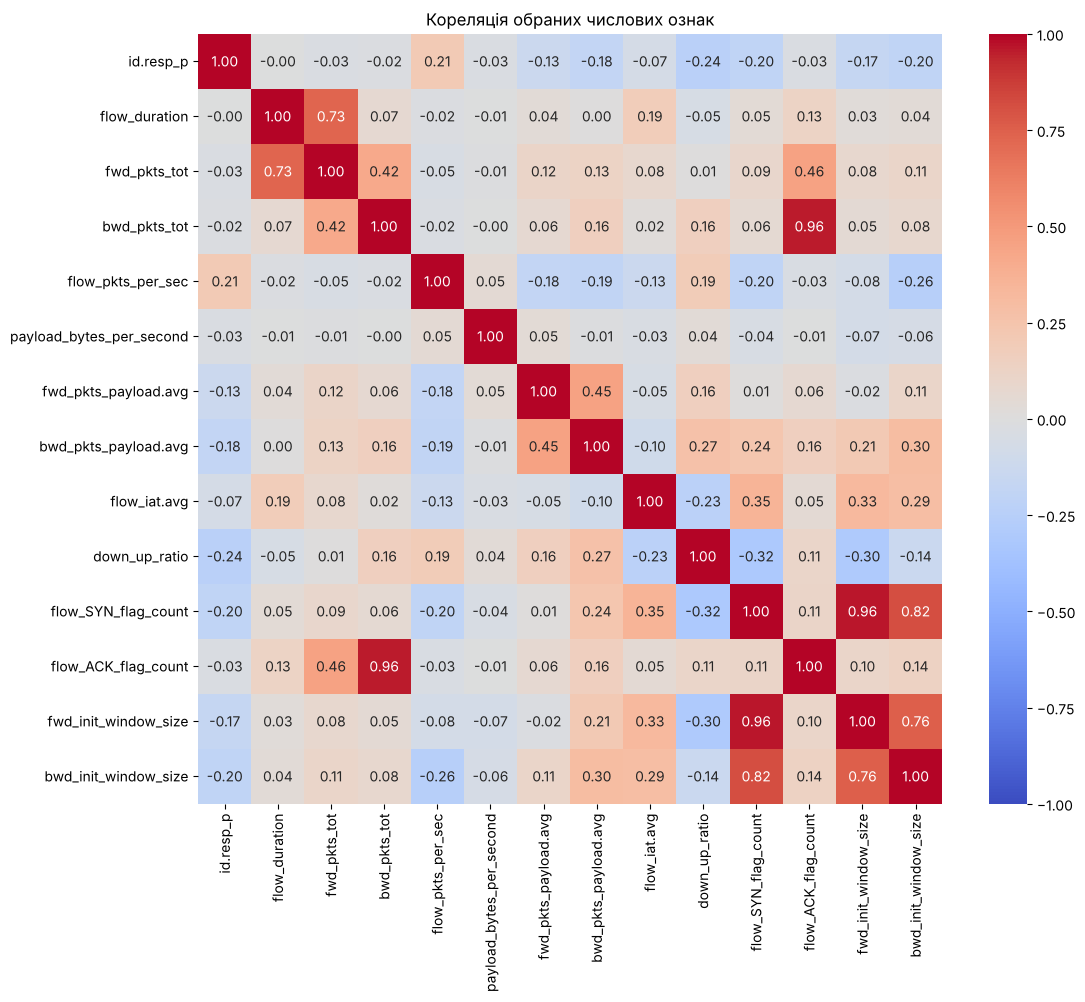

In [24]:
plt.figure(figsize=(12,10))
sns.heatmap(df[eda_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Кореляція обраних числових ознак')
plt.show()

In [25]:
corr_all = df.drop(columns=['Attack_type']).corr().abs()
upper = corr_all.where(np.triu(np.ones(corr_all.shape), k=1).astype(bool))
high_corr = upper.stack()
high_corr = high_corr[high_corr > 0.95].sort_values(ascending=False)
print('Пар ознак з |r| > 0.95:', len(high_corr))
high_corr.head(15)

Пар ознак з |r| > 0.95: 56


flow_duration     flow_iat.tot         1.000000
bwd_pkts_per_sec  flow_pkts_per_sec    0.999880
fwd_pkts_per_sec  flow_pkts_per_sec    0.999880
bwd_bulk_bytes    bwd_bulk_packets     0.999805
flow_iat.max      idle.max             0.999725
fwd_iat.tot       flow_iat.tot         0.999692
flow_duration     fwd_iat.tot          0.999692
fwd_pkts_per_sec  bwd_pkts_per_sec     0.999522
proto_tcp         proto_udp            0.996900
flow_duration     idle.tot             0.996406
flow_iat.tot      idle.tot             0.996406
fwd_iat.max       flow_iat.max         0.996083
fwd_iat.tot       idle.tot             0.996074
fwd_iat.max       idle.max             0.995811
idle.max          idle.avg             0.994264
dtype: float64

Серед обраних ознак сильно корелюють `bwd_pkts_tot` і `flow_ACK_flag_count` (0.96), `flow_SYN_flag_count` і `fwd_init_window_size` (0.96), а також `flow_duration` і `fwd_pkts_tot` (0.73). Більшість інших пар майже не пов'язані.

У всьому датасеті 56 пар ознак мають |r| > 0.95. Багато ознак обчислюються одна з одної (наприклад, `flow_duration` і `flow_iat.tot` або швидкості пакетів fwd, bwd і flow), тому це очікувано. Деревам така надлишковість не заважає, а в kNN ці ознаки фактично отримують більшу вагу у відстані. Ознаки не видалялись, щоб усі моделі навчались на однаковому наборі.

### Гістограми розподілу ознак

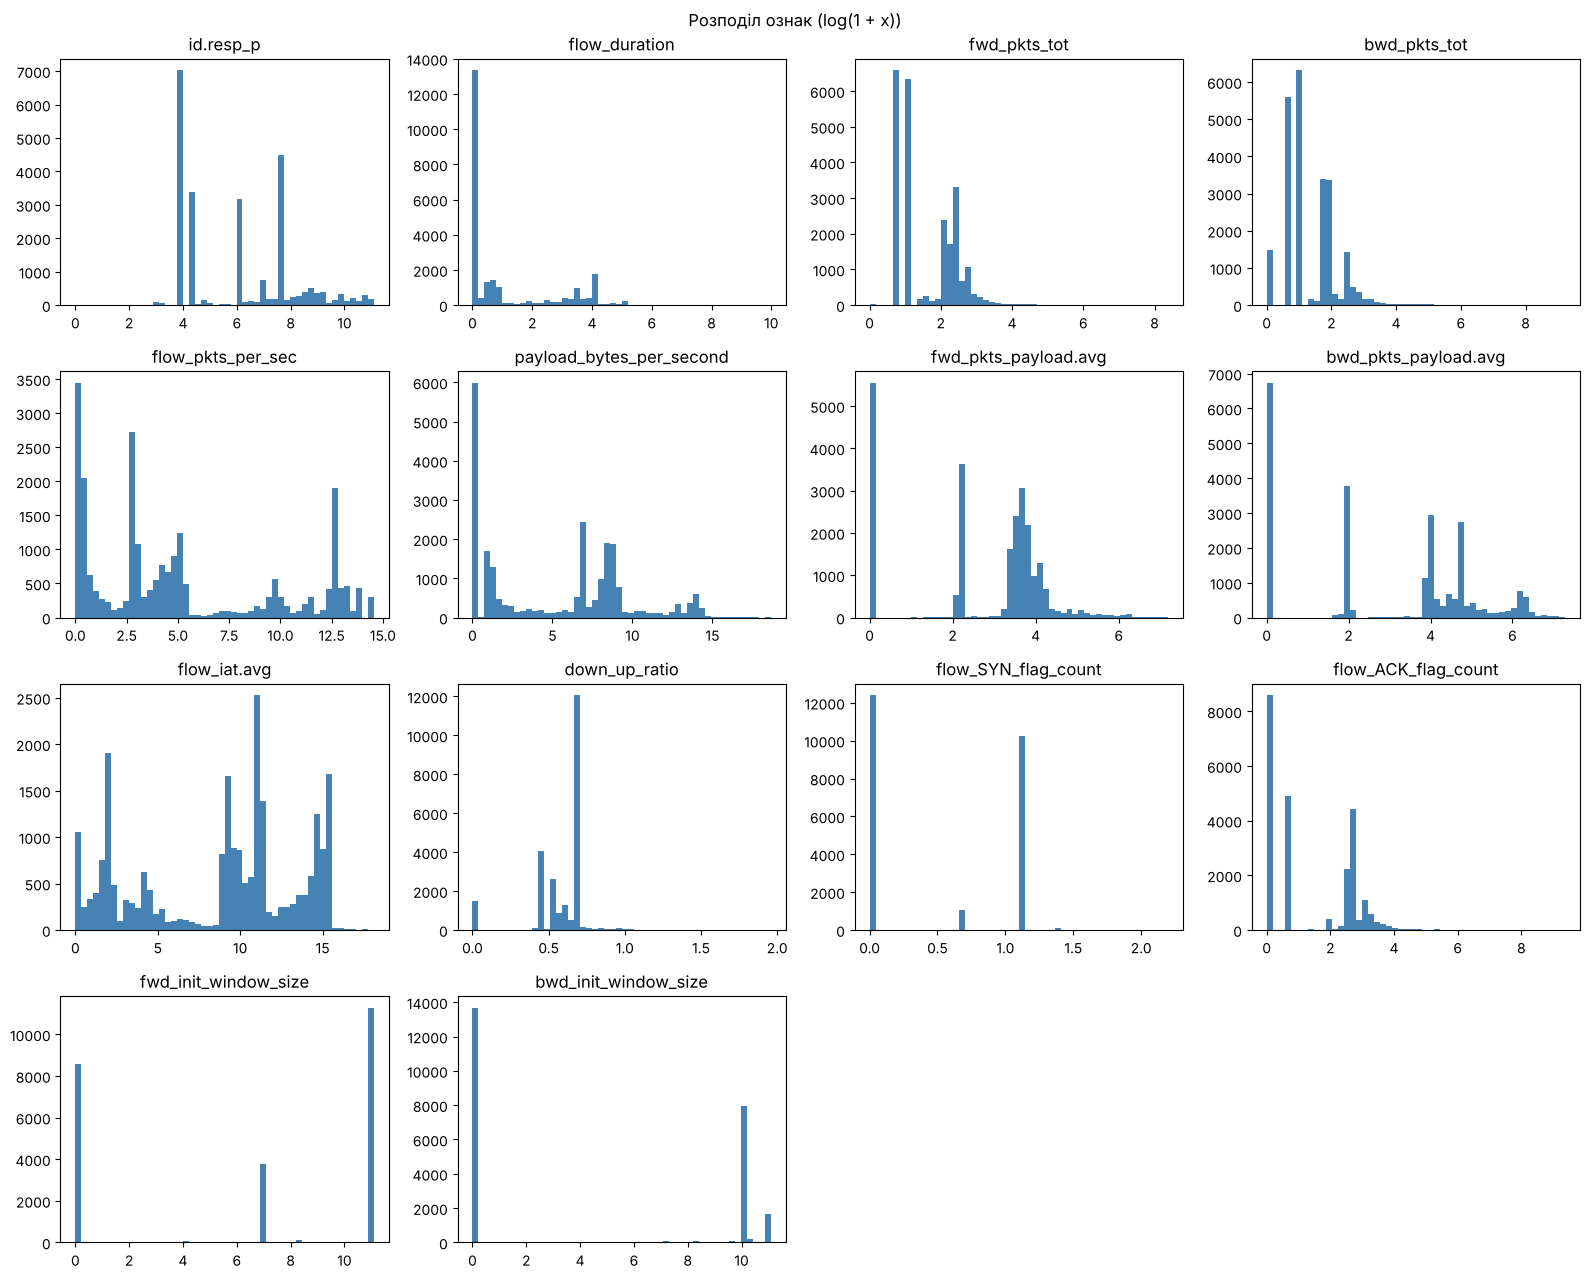

In [26]:
fig, axes = plt.subplots(4, 4, figsize=(16,13))
for ax, col in zip(axes.flat, eda_cols):
    ax.hist(np.log1p(df[col]), bins=50, color='steelblue')
    ax.set_title(col)
for ax in axes.flat[len(eda_cols):]:
    ax.axis('off')
plt.suptitle('Розподіл ознак (log(1 + x))')
plt.tight_layout()
plt.show()

Без логарифма майже кожна гістограма перетворюється на один стовпець біля нуля з довгим хвостом, тому на графіках використано log(1 + x). Розподіли далекі від нормального і мають кілька окремих піків, які відповідають різним типам трафіку. Наприклад, `fwd_init_window_size` приймає по суті три значення (0, 1024 і 64240), а `flow_SYN_flag_count` переважно дорівнює 0 або 2. У багатьох ознак велика частка нулів: це потоки без payload або без відповіді.

### Boxplot-и ознак відносно цільової змінної

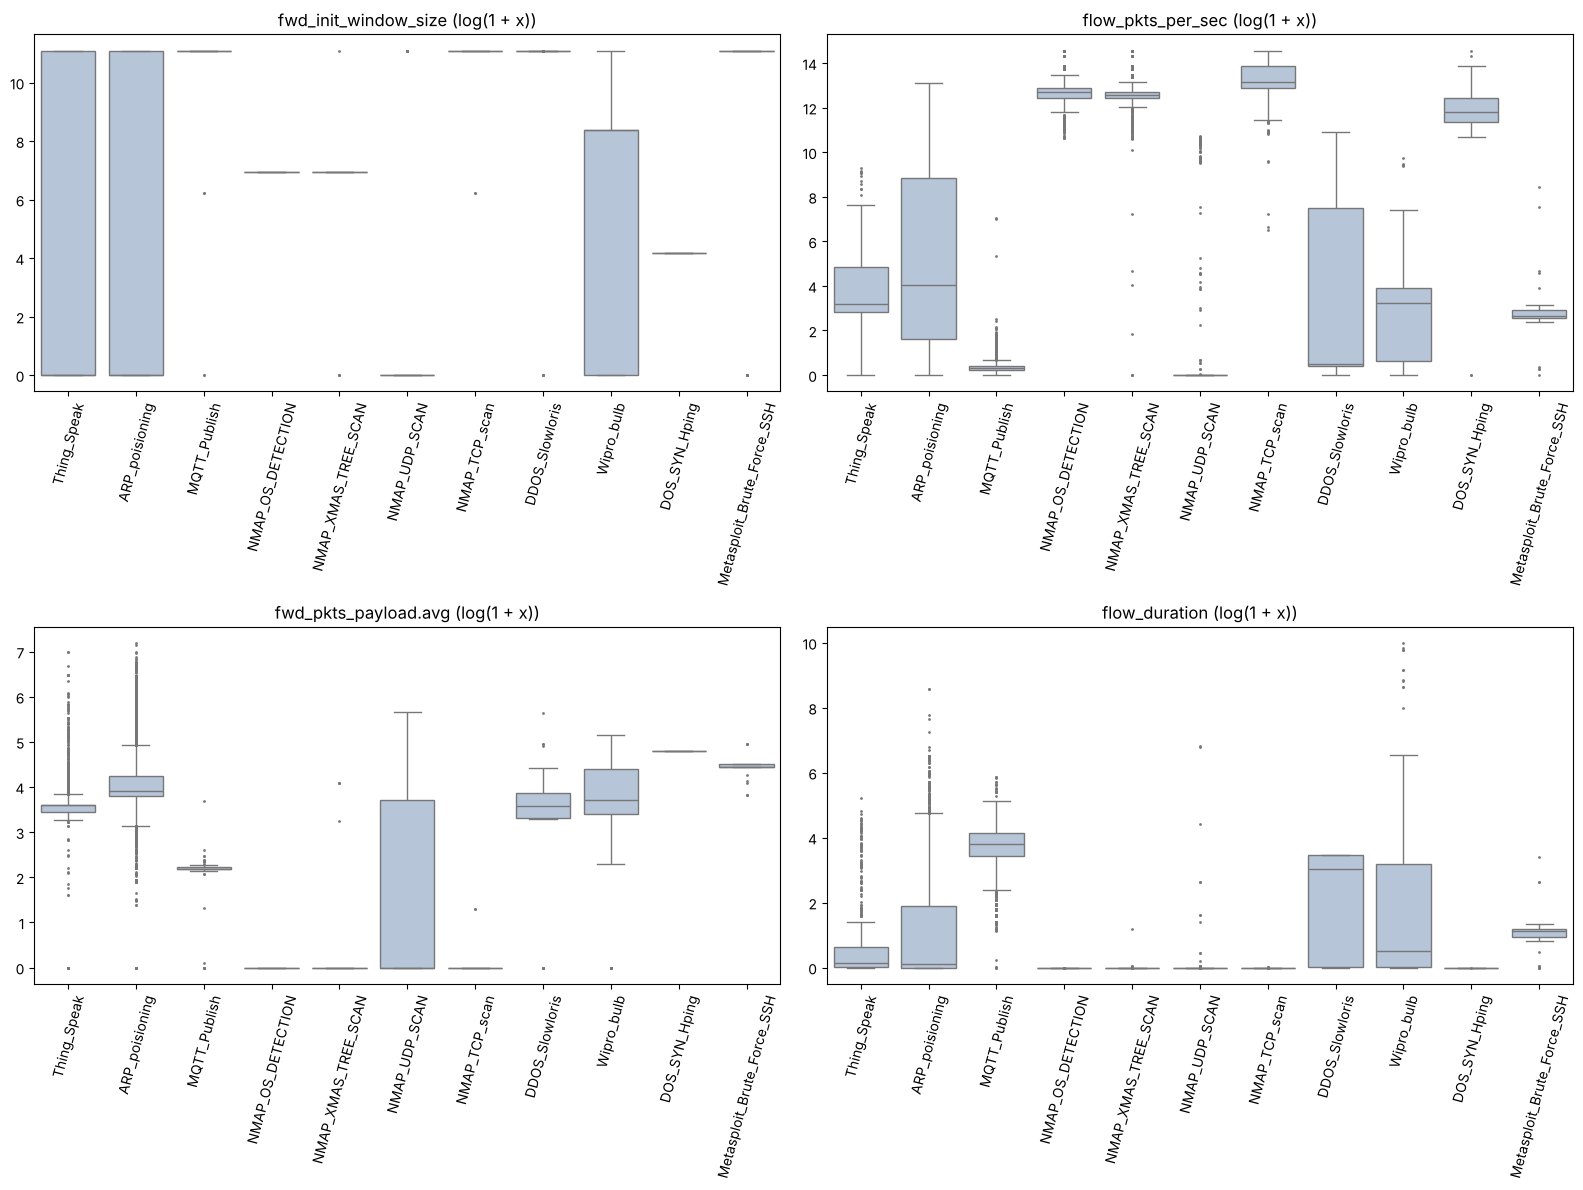

In [27]:
box_cols = ['fwd_init_window_size', 'flow_pkts_per_sec', 'fwd_pkts_payload.avg', 'flow_duration']
order = df['Attack_type'].value_counts().index

fig, axes = plt.subplots(2, 2, figsize=(16,12))
for ax, col in zip(axes.flat, box_cols):
    sns.boxplot(x=df['Attack_type'], y=np.log1p(df[col]), order=order, ax=ax, color='lightsteelblue', fliersize=1)
    ax.set_title(col + ' (log(1 + x))')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=75)
plt.tight_layout()
plt.show()

Багато класів добре відокремлюються навіть однією ознакою. Сканування NMAP (`OS_DETECTION`, `XMAS_TREE_SCAN`, `TCP_scan`) і `DOS_SYN_Hping` мають дуже високу швидкість пакетів, нульову тривалість і порожній payload, тобто це короткі потоки з одного-двох пакетів. У `NMAP_OS_DETECTION` і `NMAP_XMAS_TREE_SCAN` однакове `fwd_init_window_size` = 1024, а в `DOS_SYN_Hping` своє фіксоване значення 64. `MQTT_Publish` вирізняється довгими потоками з малим payload. Найбільше перекриваються `Thing_Speak`, `ARP_poisioning` і `Wipro_bulb`, тож саме між ними варто очікувати помилок.

## 4. Підготовка даних до навчання

In [28]:
X = df.drop(columns=['Attack_type'])
y = df['Attack_type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(19067, 92) (4767, 92)


`stratify=y` зберігає однакові пропорції класів у training та test вибірках. Без цього найменші класи (десятки записів) могли б майже не потрапити в test.

In [29]:
pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()})

,train,test
Attack_type,,
Thing_Speak,6081,1521
ARP_poisioning,4240,1060
MQTT_Publish,3313,828
NMAP_OS_DETECTION,1519,380
NMAP_XMAS_TREE_SCAN,1515,379
NMAP_UDP_SCAN,921,230
NMAP_TCP_scan,802,200
DDOS_Slowloris,426,107
Wipro_bulb,175,44


### Масштабування

kNN і SVM працюють з відстанями між об'єктами, тому чутливі до масштабу ознак: без масштабування ознаки на зразок `payload_bytes_per_second` (мільйони) повністю «заглушили» б прапорці TCP (від 0 до 10). Використано `StandardScaler` (середнє 0, стандартне відхилення 1), навчений лише на training вибірці.

Деревам (Decision Tree, Random Forest, AdaBoost на деревах) масштабування не потрібне: вони розбивають дані за порогами окремої ознаки, і зміна масштабу не змінює результат розбиття.

In [30]:
scaler = StandardScaler()
scaler.fit(X_train)

scaled_X_train = scaler.transform(X_train)
scaled_X_test = scaler.transform(X_test)

## 5. Навчання моделей і 6. Підбір гіперпараметрів

Класи сильно незбалансовані, тому, крім accuracy, головною метрикою порівняння береться macro F1, тобто середнє F1 по всіх класах без врахування їх розміру. Так помилки на малих класах (`DOS_SYN_Hping`, `Metasploit_Brute_Force_SSH`) впливають на оцінку так само, як і на великих.

In [31]:
results = {}

def evaluate(name, y_pred):
    results[name] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'macro F1': f1_score(y_test, y_pred, average='macro'),
        'weighted F1': f1_score(y_test, y_pred, average='weighted')
    }
    print(confusion_matrix(y_test, y_pred))
    print()
    print(classification_report(y_test, y_pred, digits=3, zero_division=0))

### 5.1 k-Nearest Neighbors

In [32]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(scaled_X_train, y_train)
pred = knn.predict(scaled_X_test)
evaluate('kNN (k=5)', pred)

[[1036    0    0    0    0    0    3    3    0   17    1]
 [   1   97    0    0    0    0    0    8    0    1    0]
 [   0    0   11    0    0    0    0    0    0    0    0]
 [   0    2    0  826    0    0    0    0    0    0    0]
 [   2    0    0    0    5    0    0    0    0    0    0]
 [   0    0    0    0    0  380    0    0    0    0    0]
 [   1    0    0    1    0    0  198    0    0    0    0]
 [   6    5    0    0    0    0    0  216    0    3    0]
 [   0    0    0    0    0    0    0    1  378    0    0]
 [  23    0    0    0    0    1    0    2    0 1493    2]
 [   3    0    0    2    0    0    0    0    0    3   36]]

                            precision    recall  f1-score   support

            ARP_poisioning      0.966     0.977     0.972      1060
            DDOS_Slowloris      0.933     0.907     0.919       107
             DOS_SYN_Hping      1.000     1.000     1.000        11
              MQTT_Publish      0.996     0.998     0.997       828
Metasploit_Brute_Fo

#### Підбір n_neighbors

Значення `k` підбирається крос-валідацією (5 фолдів) лише на training вибірці, щоб test залишався «новими» даними для фінальної оцінки.

In [33]:
knn_params = {'n_neighbors': range(1, 21)}
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_params, cv=5, scoring='f1_macro', n_jobs=-1)
knn_grid.fit(scaled_X_train, y_train)
knn_grid.best_params_

{'n_neighbors': 1}

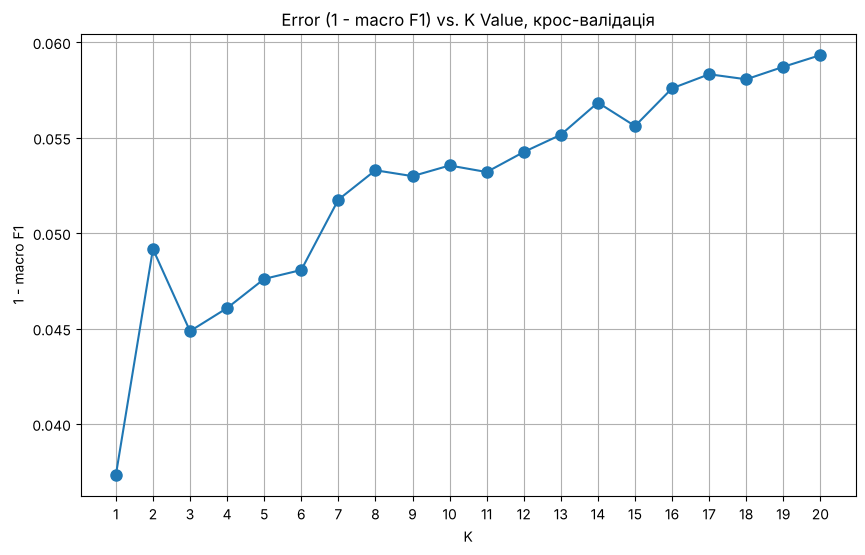

In [34]:
plt.figure(figsize=(10,6))
plt.plot(range(1, 21), 1 - knn_grid.cv_results_['mean_test_score'], marker='o', markersize=8)
plt.title('Error (1 - macro F1) vs. K Value, крос-валідація')
plt.xlabel('K')
plt.ylabel('1 - macro F1')
plt.xticks(range(1, 21))
plt.grid()
plt.show()

На крос-валідації найкращий результат дає k = 1, а далі помилка майже рівномірно зростає. Причина в малих класах: у `DOS_SYN_Hping` і `Metasploit_Brute_Force_SSH` лише кілька десятків записів у train, і при великому k сусіди з великих класів їх «переважують». Водночас k = 1 чутливий до шуму, бо рішення залежить від одного найближчого об'єкта. Нижче модель перенавчено з k = 1 і оцінено на test.

In [35]:
best_k = knn_grid.best_params_['n_neighbors']
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(scaled_X_train, y_train)
pred = knn.predict(scaled_X_test)
evaluate(f'kNN (k={best_k})', pred)

[[1043    0    0    0    2    0    0    3    0   11    1]
 [   0   96    0    0    0    0    0   10    0    1    0]
 [   0    0   11    0    0    0    0    0    0    0    0]
 [   0    1    0  827    0    0    0    0    0    0    0]
 [   2    0    0    0    5    0    0    0    0    0    0]
 [   0    0    0    0    0  380    0    0    0    0    0]
 [   0    0    0    0    0    0  200    0    0    0    0]
 [   1    9    0    0    1    0    0  215    0    4    0]
 [   0    0    0    0    0    0    0    1  378    0    0]
 [  20    0    0    1    0    0    0    2    0 1496    2]
 [   1    0    0    1    0    0    0    0    0    2   40]]

                            precision    recall  f1-score   support

            ARP_poisioning      0.978     0.984     0.981      1060
            DDOS_Slowloris      0.906     0.897     0.901       107
             DOS_SYN_Hping      1.000     1.000     1.000        11
              MQTT_Publish      0.998     0.999     0.998       828
Metasploit_Brute_Fo

### 5.2 Decision Tree

In [36]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)
pred = tree.predict(X_test)
evaluate('Decision Tree', pred)

[[1039    1    0    0    2    1    0    5    1   10    1]
 [   2   98    0    0    0    0    0    7    0    0    0]
 [   0    0   11    0    0    0    0    0    0    0    0]
 [   0    0    0  828    0    0    0    0    0    0    0]
 [   2    0    0    0    4    0    0    0    0    0    1]
 [   0    0    0    0    0  380    0    0    0    0    0]
 [   1    0    0    0    0    0  199    0    0    0    0]
 [   4    7    0    0    1    0    0  217    0    1    0]
 [   0    0    0    0    0    0    0    1  378    0    0]
 [  25    0    0    1    1    0    0    1    0 1488    5]
 [   1    2    0    0    1    0    0    0    0    1   39]]

                            precision    recall  f1-score   support

            ARP_poisioning      0.967     0.980     0.974      1060
            DDOS_Slowloris      0.907     0.916     0.912       107
             DOS_SYN_Hping      1.000     1.000     1.000        11
              MQTT_Publish      0.999     1.000     0.999       828
Metasploit_Brute_Fo

In [37]:
print('Глибина дерева:', tree.get_depth(), ' Кількість листків:', tree.get_n_leaves())

Глибина дерева: 17  Кількість листків: 282


Додатково перевірено, як на результат впливає обмеження глибини дерева `max_depth`.

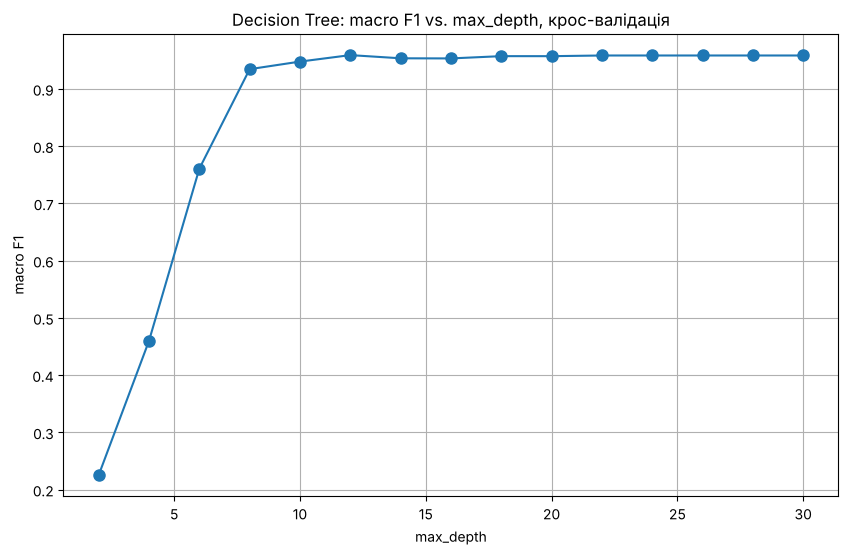

{'max_depth': 12}

In [38]:
tree_grid = GridSearchCV(DecisionTreeClassifier(random_state=42), {'max_depth': range(2, 31, 2)}, cv=5, scoring='f1_macro', n_jobs=-1)
tree_grid.fit(X_train, y_train)

plt.figure(figsize=(10,6))
plt.plot(range(2, 31, 2), tree_grid.cv_results_['mean_test_score'], marker='o', markersize=8)
plt.title('Decision Tree: macro F1 vs. max_depth, крос-валідація')
plt.xlabel('max_depth')
plt.ylabel('macro F1')
plt.grid()
plt.show()
tree_grid.best_params_

При max_depth від 2 до 6 дерево недонавчене (при глибині 2 macro F1 лише 0.23). Приблизно з глибини 10 якість виходить на плато близько 0.96 і далі майже не змінюється. GridSearchCV обрав max_depth = 12, але різниця з деревом без обмеження (глибина 17) мізерна, тому в порівнянні залишено дерево з параметрами за замовчуванням.

### 5.3 Support Vector Machine

In [39]:
svm = SVC(kernel='rbf')
svm.fit(scaled_X_train, y_train)
pred = svm.predict(scaled_X_test)
evaluate('SVM (C=1, gamma=scale)', pred)

[[1026    0    0    0    0    0    3    0    0   31    0]
 [   1   85    0    0    0    0    0   20    0    1    0]
 [   0    0   11    0    0    0    0    0    0    0    0]
 [   1    0    0  827    0    0    0    0    0    0    0]
 [   2    0    0    0    5    0    0    0    0    0    0]
 [   0    0    0    0    0  380    0    0    0    0    0]
 [   1    0    0    0    0    0  198    0    0    0    1]
 [   4    0    0    0    0    0    0  220    0    6    0]
 [   1    0    0    0    0    0    0    0  378    0    0]
 [  53    0    0    0    0    0    0    1    0 1466    1]
 [   3    0    0    0    0    0    0    0    0    7   34]]

                            precision    recall  f1-score   support

            ARP_poisioning      0.940     0.968     0.954      1060
            DDOS_Slowloris      1.000     0.794     0.885       107
             DOS_SYN_Hping      1.000     1.000     1.000        11
              MQTT_Publish      1.000     0.999     0.999       828
Metasploit_Brute_Fo

#### GridSearchCV для C та gamma

* `C` задає силу регуляризації: велике `C` змушує модель правильно класифікувати майже кожну точку навчальної вибірки (ризик перенавчання), мале `C` дає простішу межу.
* `gamma` визначає радіус впливу однієї точки для RBF-ядра: мале `gamma` дає гладку межу, велике дає дуже «звивисту».

In [40]:
param_grid = {'C': [0.1, 1, 10, 100, 1000], 'gamma': [1, 0.1, 0.01, 0.001], 'kernel': ['rbf']}
grid = GridSearchCV(SVC(), param_grid, cv=5, scoring='f1_macro', refit=True, n_jobs=-1)
grid.fit(scaled_X_train, y_train)
grid.best_params_

{'C': 1000, 'gamma': 0.01, 'kernel': 'rbf'}

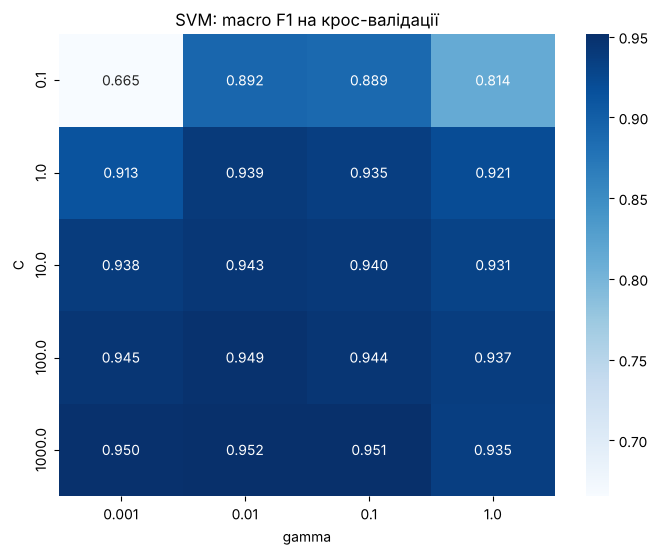

In [41]:
scores = pd.DataFrame(grid.cv_results_).pivot(index='param_C', columns='param_gamma', values='mean_test_score')
plt.figure(figsize=(8,6))
sns.heatmap(scores, annot=True, fmt='.3f', cmap='Blues')
plt.title('SVM: macro F1 на крос-валідації')
plt.xlabel('gamma')
plt.ylabel('C')
plt.show()

Найгірші результати при C = 0.1: сильна регуляризація дає надто просту межу. Зі збільшенням C якість росте, і найкращою виявилась комбінація C = 1000, gamma = 0.01 (macro F1 0.952 на крос-валідації). При gamma = 1 результат гірший для будь-якого C, бо межа починає підлаштовуватись під окремі точки. Значення C = 1000 крайнє в сітці, тож більші C могли б дати ще трохи кращий результат, але між C = 100 і C = 1000 різниця вже невелика (0.949 і 0.952).

In [42]:
grid_predictions = grid.predict(scaled_X_test)
evaluate(f"SVM (C={grid.best_params_['C']}, gamma={grid.best_params_['gamma']})", grid_predictions)

[[1032    0    0    0    0    0    0    2    0   26    0]
 [   1   85    0    0    0    0    0   20    0    1    0]
 [   0    0   11    0    0    0    0    0    0    0    0]
 [   0    0    0  828    0    0    0    0    0    0    0]
 [   2    0    0    0    5    0    0    0    0    0    0]
 [   0    0    0    0    0  380    0    0    0    0    0]
 [   0    0    0    0    0    0  200    0    0    0    0]
 [   3    1    0    0    0    0    0  222    0    4    0]
 [   1    0    0    0    0    0    0    0  378    0    0]
 [  32    0    0    1    0    0    0    0    0 1486    2]
 [   2    0    0    1    0    0    0    0    0    1   40]]

                            precision    recall  f1-score   support

            ARP_poisioning      0.962     0.974     0.968      1060
            DDOS_Slowloris      0.988     0.794     0.881       107
             DOS_SYN_Hping      1.000     1.000     1.000        11
              MQTT_Publish      0.998     1.000     0.999       828
Metasploit_Brute_Fo

### 5.4 Random Forest

In [43]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
evaluate('Random Forest', pred)

[[1050    0    0    0    1    0    0    3    0    6    0]
 [   1   97    0    0    0    0    0    8    0    1    0]
 [   0    0   11    0    0    0    0    0    0    0    0]
 [   0    0    0  828    0    0    0    0    0    0    0]
 [   2    0    0    0    5    0    0    0    0    0    0]
 [   0    0    0    0    0  380    0    0    0    0    0]
 [   0    0    0    0    0    0  200    0    0    0    0]
 [   2    5    0    0    1    0    0  222    0    0    0]
 [   0    0    0    0    0    0    0    1  378    0    0]
 [  20    0    0    0    0    0    0    2    0 1498    1]
 [   1    0    0    0    0    0    0    0    0    1   42]]

                            precision    recall  f1-score   support

            ARP_poisioning      0.976     0.991     0.983      1060
            DDOS_Slowloris      0.951     0.907     0.928       107
             DOS_SYN_Hping      1.000     1.000     1.000        11
              MQTT_Publish      1.000     1.000     1.000       828
Metasploit_Brute_Fo

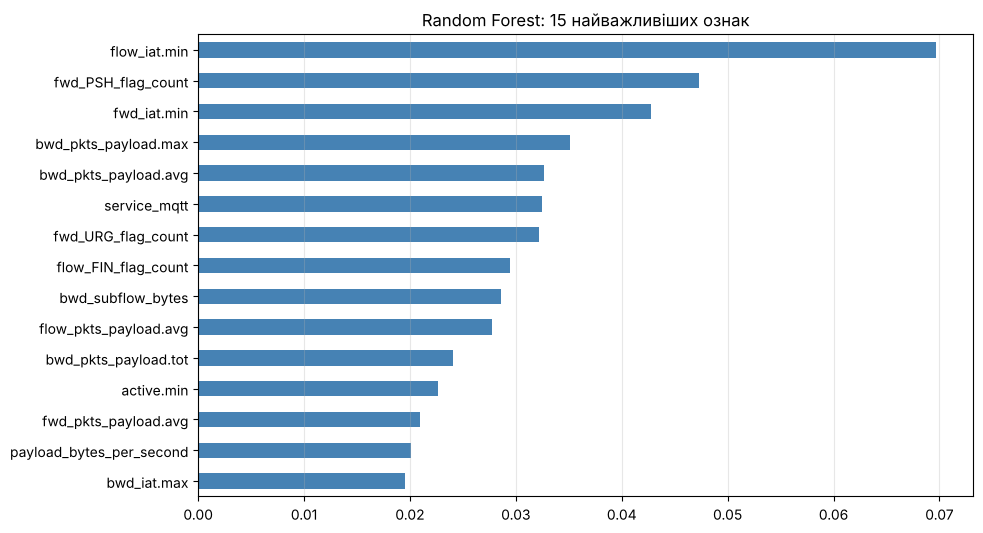

In [44]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10,6))
importances.head(15).sort_values().plot(kind='barh', color='steelblue')
plt.title('Random Forest: 15 найважливіших ознак')
plt.grid(axis='x', alpha=0.3)
plt.show()

Для Random Forest найважливіші ознаки описують час між пакетами (`flow_iat.min`, `fwd_iat.min`), TCP-прапорці (PSH, URG, FIN) та розмір payload. У топ також потрапила `service_mqtt` з one-hot кодування, яка майже однозначно відділяє `MQTT_Publish`.

### 5.5 AdaBoost

За замовчуванням AdaBoost використовує як слабкий класифікатор decision stump (дерево глибини 1).

In [45]:
ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)
pred = ada.predict(X_test)
evaluate('AdaBoost (stumps)', pred)

[[ 973    1    0    0    0    0    0    9    0   77    0]
 [   1   55    0    0    0    0    0   21    0   30    0]
 [   0    0    1    0    0   10    0    0    0    0    0]
 [   0    0    0  828    0    0    0    0    0    0    0]
 [   6    1    0    0    0    0    0    0    0    0    0]
 [   0    0    0    0    0  380    0    0    0    0    0]
 [   1    0    0    0    0  194    4    1    0    0    0]
 [   8    0    0    0    0    0    0  219    0    3    0]
 [   1    0    0    0    0    0    0    0  378    0    0]
 [ 242    0    0    0    0    0    0    6    0 1273    0]
 [   5    0    0    0    0    0    0    3    0   28    8]]

                            precision    recall  f1-score   support

            ARP_poisioning      0.787     0.918     0.847      1060
            DDOS_Slowloris      0.965     0.514     0.671       107
             DOS_SYN_Hping      1.000     0.091     0.167        11
              MQTT_Publish      1.000     1.000     1.000       828
Metasploit_Brute_Fo

AdaBoost на stump-ах працює значно гірше (accuracy 0.864, macro F1 0.598). Дерево глибини 1 робить лише одне розбиття, і для 11 класів цього замало: `Metasploit_Brute_Force_SSH`, `NMAP_TCP_scan` і `DOS_SYN_Hping` модель майже не розпізнає. Для порівняння нижче AdaBoost навчено на деревах глибини 3.

In [46]:
ada3 = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3), n_estimators=100, random_state=42)
ada3.fit(X_train, y_train)
pred = ada3.predict(X_test)
evaluate('AdaBoost (max_depth=3)', pred)

[[ 979    0    0    0    0    0    0    1    0   80    0]
 [   4   82    0    0    0    0    0   20    0    1    0]
 [   0    0   11    0    0    0    0    0    0    0    0]
 [   1    0    0  827    0    0    0    0    0    0    0]
 [   3    0    0    0    4    0    0    0    0    0    0]
 [   0    0    0    0    0  380    0    0    0    0    0]
 [   1    0    0    0    0    0  199    0    0    0    0]
 [   3    1    0    0    1    0    0  221    0    4    0]
 [   1    0    0    0    0    0    0    0  378    0    0]
 [  20    0    0    0    0    0    0    2    0 1499    0]
 [   1    0    0    0    0    0    0    0    0    1   42]]

                            precision    recall  f1-score   support

            ARP_poisioning      0.966     0.924     0.945      1060
            DDOS_Slowloris      0.988     0.766     0.863       107
             DOS_SYN_Hping      1.000     1.000     1.000        11
              MQTT_Publish      1.000     0.999     0.999       828
Metasploit_Brute_Fo

## 7. Порівняння та оцінювання моделей

In [47]:
results_df = pd.DataFrame(results).T.sort_values('macro F1', ascending=False)
results_df.round(4)

,accuracy,macro F1,weighted F1
Random Forest,0.9883,0.9575,0.9883
"SVM (C=1000, gamma=0.01)",0.9790,0.9567,0.9788
kNN (k=5),0.9809,0.9542,0.9808
"SVM (C=1, gamma=scale)",0.9713,0.9463,0.9710
kNN (k=1),0.9841,0.9440,0.9841
AdaBoost (max_depth=3),0.9696,0.9404,0.9692
Decision Tree,0.9820,0.9247,0.9821
AdaBoost (stumps),0.8641,0.5984,0.8445


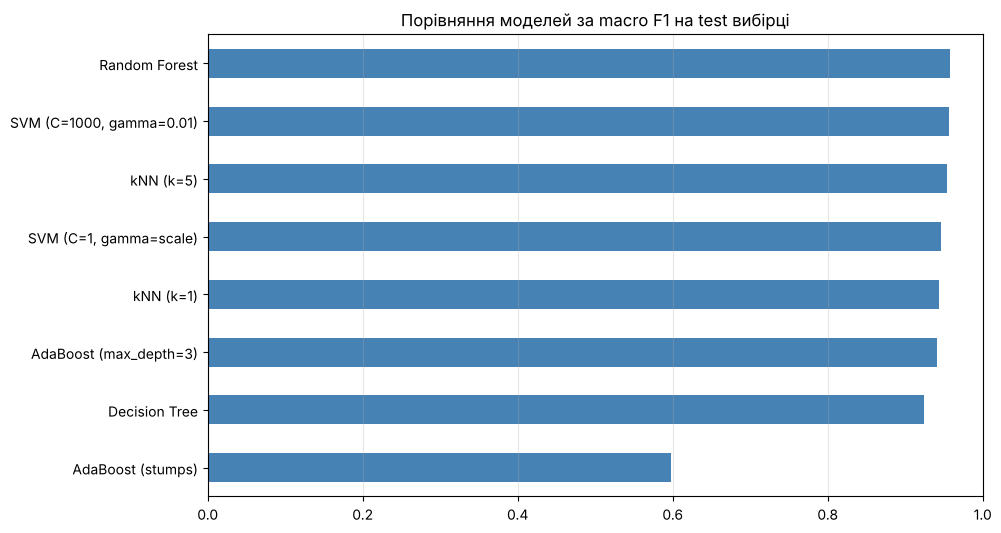

In [48]:
plt.figure(figsize=(10,6))
results_df['macro F1'].sort_values().plot(kind='barh', color='steelblue')
plt.title('Порівняння моделей за macro F1 на test вибірці')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.3)
plt.show()

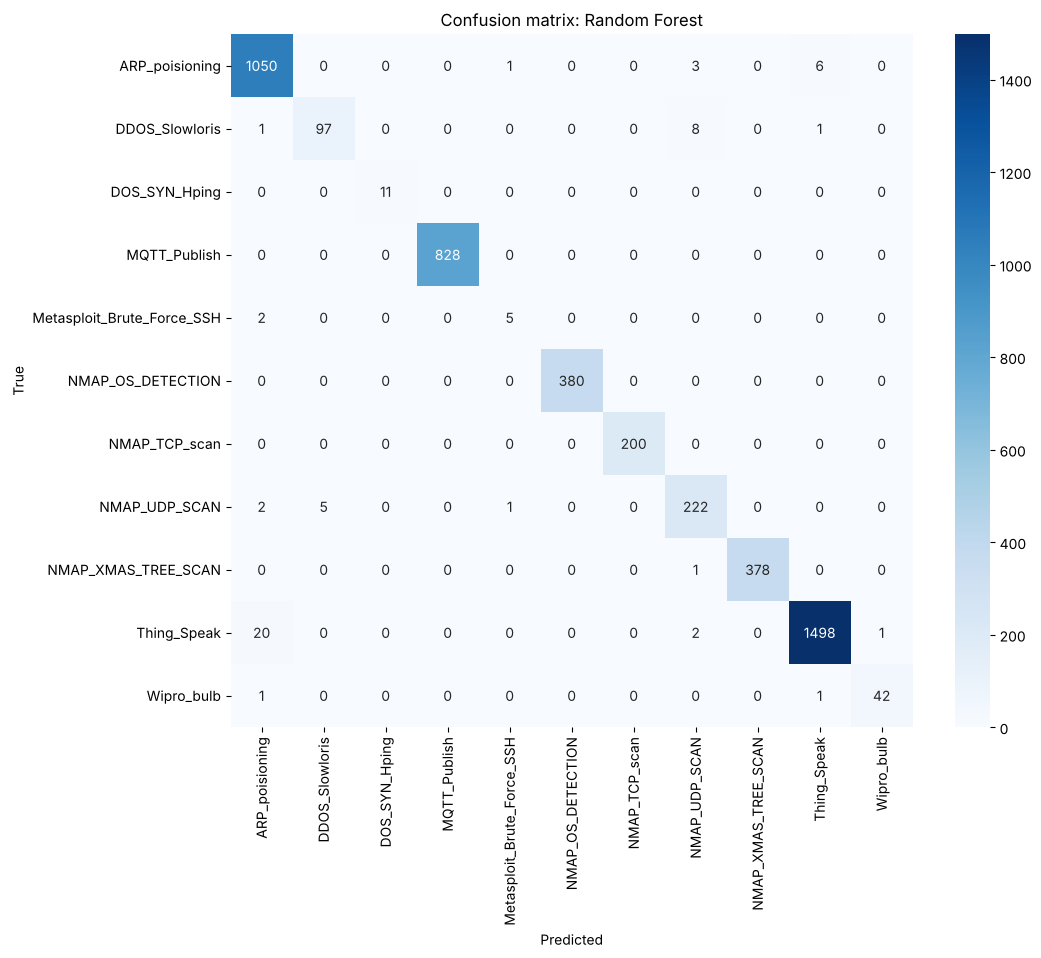

In [49]:
cm = confusion_matrix(y_test, rf.predict(X_test), labels=rf.classes_)
plt.figure(figsize=(11,9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=rf.classes_, yticklabels=rf.classes_)
plt.title('Confusion matrix: Random Forest')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

Більшість помилок Random Forest припадає на пару `Thing_Speak` і `ARP_poisioning`: 20 потоків `Thing_Speak` класифіковано як `ARP_poisioning`, і ще 6 помилок у зворотний бік. Це збігається з boxplot-ами, де ці класи сильно перекриваються. Також 8 потоків `DDOS_Slowloris` потрапили в `NMAP_UDP_SCAN` і 5 у зворотний бік. З 7 тестових записів `Metasploit_Brute_Force_SSH` правильно визначено 5. Сканування NMAP, `MQTT_Publish` і `DOS_SYN_Hping` розпізнаються без помилок або майже без них.

## Висновок

Найкращий результат показав Random Forest: accuracy 0.988 і macro F1 0.958. SVM з підібраними C = 1000 і gamma = 0.01 має майже такий самий macro F1 (0.957), але нижчу accuracy (0.979). До того ж SVM потребує масштабування, а підбір його параметрів займає значно більше часу.

Random Forest добре підходить для цих даних. Ознаки мають скошені розподіли з великою кількістю нулів і дуже різні масштаби, а для дерев масштаб і форма розподілу не мають значення. Багато класів відділяються порогами за окремими ознаками (розмір TCP-вікна, кількість прапорців, швидкість пакетів), а саме так дерева й будують розбиття. Одне дерево при цьому перенавчається (macro F1 0.925), а усереднення 100 дерев, навчених на різних підвибірках об'єктів і ознак, зменшує цей ефект.

kNN теж показав хороший результат (macro F1 0.954 при k = 5), але він залежить від масштабування і повільно працює на великих вибірках. Обране крос-валідацією k = 1 на test дало вищу accuracy, ніж k = 5, але нижчий macro F1. Різниця виникла через `Metasploit_Brute_Force_SSH`: у test цього класу лише 7 записів, тому одна помилка помітно змінює його F1. AdaBoost на деревах глибини 3 (macro F1 0.940) значно кращий за варіант зі stump-ами, але поступається Random Forest.

Основне обмеження роботи: малі класи `DOS_SYN_Hping` і `Metasploit_Brute_Force_SSH` мають у test лише 11 і 7 записів, тому метрики для них нестабільні. Через це різниця між найкращими моделями в тисячні частки macro F1 не є суттєвою.